# Reproducibility package paths and historical outputs

Original source: `/data/hulei/HongtaoYu_Lab/Fetal_brain/Revision/GRN/T577_SpaGRN_bin100_lowdown.ipynb`.
Original file SHA256: `e4a6a5c87ee42a57a4f5c26dffab9bdd678a0fbeb97101a4a50c241f8b16095c`.

**This notebook was not re-executed or retrained for this update. All execution counts and cell outputs below are preserved from the original notebook as historical records. The updated paths have not been runtime-validated.**

Run from the `reproducibility` package root, where `base = Path.cwd()` and `config.json` provides the runtime inputs. By default, the notebook reads the original external input matrix. New training results, temporary files, downsampled matrices, and QC files are written outside the package under `../reproducibility_work`. Original inputs, prior results, and package data are not written back.

Inference parameters, random seeds, constant-gene handling, and AUCell settings are unchanged. The two ranking databases use their exact configured file paths.


# T577 bin100 downsampling: SpaGRN

Uses SpaGRN’s native stepwise interface：spatial co-expression → modules → cisTarget → AUCell。Retains the original notebook’s Moran statistic, 30 neighbors, and intersection of four FDR criteria; all 117,867 bins and all genes are retained.

The reference consists of two cisTarget databases built from the native Macaca fascicularis 5.0 / Ensembl 91 sequences. The input is bin100 data aggregated using representative cell coordinates. Counts reconstructed as `round(expm1(expr))` have not been confirmed to represent raw UMI counts. Cell-type labels are unavailable, so RSS is not calculated.

[Official tutorial](https://spagrn.readthedocs.io/en/latest/content/01_Basic_Usage.html). Local SpaGRN version: 1.1.4. Spatial statistics use its native GPU interface, and Moran co-expression uses the native CPU implementation.

For each bin, sample `floor(source total counts / 2)` counts without replacement using seed 20261016. Detected-gene counts are unconstrained and vary naturally with count sampling. Retain all bins, all 15,541 gene columns, and coordinates. Spatial statistics use only non-constant genes; AUCell retains the full gene background.


In [1]:
from pathlib import Path
import json
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from spagrn.regulatory_network import InferNetwork

base = Path.cwd()
config = json.loads((base / "config.json").read_text())["training"]
run = config["runs"][0]
out = base / run["output_dir"]
out.mkdir(parents=True, exist_ok=True)
adata = sc.read_h5ad(base / run["input"])
# Exclude only constant genes, which spatial statistics cannot process; retain all bins and gene columns in the final output.
counts = adata.X.astype("float64").tocsc()
variable = np.asarray(counts.power(2).mean(axis=0)).ravel() > np.asarray(counts.mean(axis=0)).ravel() ** 2
analysis = adata[:, variable].copy()
analysis.layers["raw_counts"] = counts[:, variable]
adata.var["spagrn_variable_for_training"] = variable
print("Training genes:", analysis.n_vars, "/", adata.n_vars, "(zero-variance genes excluded)")
adata


/data/lvyongji/envs/conda_envs/spagrn/lib/python3.8/site-packages/geopandas/_compat.py:124: UserWarning: The Shapely GEOS version (3.11.4-CAPI-1.17.4) is incompatible with the GEOS version PyGEOS was compiled with (3.10.4-CAPI-1.16.2). Conversions between both will be slow.
  warnings.warn(


Training genes: 15539 / 15541 (zero-variance genes excluded)


AnnData object with n_obs × n_vars = 117867 × 15541
    obs: 'orig.ident', 'x', 'y', 'total_counts', 'n_genes_by_counts'
    var: 'total_counts', 'n_cells_by_counts', 'spagrn_variable_for_training'
    uns: 'bin_size', 'bin_type', 'binning', 'counts_provenance', 'key_record', 'merged', 'sn', 'source_metadata'
    obsm: 'spatial'

In [2]:
reference = config["reference"]
grn = InferNetwork(analysis, project_name="T577_SpaGRN_bin100_lowdown")
grn.tmp_dir = str(out / "tmp_files")
Path(grn.tmp_dir).mkdir(exist_ok=True)
tfs = grn.load_tfs(str(base / reference["tf_list_file"]))
dbs = [database for ranking_file in reference["ranking_files"]
       for database in grn.load_database(ranking_file)]


## Spatial co-expression


In [3]:
adj = grn.spg(
    analysis, tf_list=tfs, layer_key="raw_counts", latent_obsm_key="spatial",
    umi_counts_obs_key="total_counts", model="bernoulli", n_neighbors=30,
    weighted_graph=False, jobs=16, local=False, combine=False,
    methods=["FDR_C", "FDR_I", "FDR_G", "FDR"], operation="intersection",
    mode="moran", torch_device="cuda:0", save_tmp=True, cache=False,
    fn=str(out / "T577_SpaGRN_bin100_lowdown.adjacencies.csv"),
)


[spg] Entering spg method
[spg] No cached file found, computing new correlations
[spg] No gene_list provided, computing from hotspot


[spg] Creating KNN graph...


[spg] KNN graph created in 22.78 seconds
[spg] Computing autocorrelations...


  0%|          | 0/15539 [00:00<?, ?it/s]

  0%|          | 1/15539 [00:00<2:55:07,  1.48it/s]

  0%|          | 8/15539 [00:00<19:30, 13.27it/s]  

... (2,226 outputs left out)

Getis G computed in 12.51 seconds
[spg] Saving more_stats to file...
[spg] Calling select_genes...
global spatial gene num (intersection): 4007
[spg] Selected 4007 genes
[spg] Gene selection completed in 3.06 minutes (183.58 seconds)
[spg] Current mode is moran
[spg] Computing local correlations in moran mode...
[spg] Computing flat weights...
[spg] Computing global bivariate Moran...


run_in_parallel_m: Total time taken: 7757.2576 seconds


[spg] Local correlations computed in 2.16 hours (9.47 minutes)
[spg] Processing local_correlations...
[spg] Saving local_correlations to file...


[spg] Exiting spg method


## Co-expression modules and cisTarget


In [4]:
matrix = adata.to_df()
modules = grn.get_modules(adj, matrix, rho_mask_dropouts=False, save_tmp=True, cache=False)
regulons = grn.prune_modules(
    modules, dbs, reference["motif_annotation_file"], num_workers=8,
    rank_threshold=1500, auc_threshold=0.05, nes_threshold=3.0,
    motif_similarity_fdr=0.05, save_tmp=True, cache=False,
    fn=str(out / "T577_SpaGRN_bin100_lowdown.motifs.csv"),
)


[get_modules] Entering get_modules method
[get_modules] Computing modules from adjacencies...



2026-10-26 04:08:24,556 - pyscenic.utils - INFO - Calculating Pearson correlations.



2026-10-26 04:08:25,040 - pyscenic.utils - WARNING - Note on correlation calculation: the default behaviour for calculating the correlations has changed after pySCENIC verion 0.9.16. Previously, the default was to calculate the correlation between a TF and target gene using only cells with non-zero expression values (mask_dropouts=True). The current default is now to use all cells to match the behavior of the R verision of SCENIC. The original settings can be retained by setting 'rho_mask_dropouts=True' in the modules_from_adjacencies function, or '--mask_dropouts' from the CLI.
	Dropout masking is currently set to [False].



2026-10-26 04:09:35,870 - pyscenic.utils - INFO - Creating modules.


[get_modules] Created 2072 modules in 1.41 minutes (84.32 seconds)
[get_modules] Saving modules to file...


[get_modules] Exiting get_modules method


... (2,007 outputs left out)

[#####################################   ] | 92% Completed | 207.68 s

[#####################################   ] | 92% Completed | 207.78 s

[########################################] | 100% Completed | 207.88 s

Motif enrichment computed in 3.49 minutes (209.24 seconds)
Create regulons from a dataframe of enriched features.
Additional columns saved: []


## AUCell activity for all bins and saving results


In [5]:
auc_mtx = grn.cal_auc(
    matrix, regulons, auc_threshold=0.05, num_workers=1, seed=20261014,
    normalize=False, cache=False, save_tmp=False,
)
adata.obsm["auc_mtx"] = auc_mtx.reindex(adata.obs_names)
adata.uns["adj"] = adj
adata.uns["regulon_dict"] = grn.regulon_dict
adata.uns["method"] = "SpaGRN"
adata.uns["spagrn_reference_species"] = reference["species"]
adata.uns["spagrn_parameters"] = dict(mode="moran", n_neighbors=30, fdr_threshold=0.05,
    operation="intersection", methods=["FDR_C", "FDR_I", "FDR_G", "FDR"],
    rank_threshold=1500, prune_auc_threshold=0.05, nes_threshold=3.0, auc_threshold=0.05)
adata.write_h5ad(out / "T577_SpaGRN_bin100_lowdown.h5ad", compression="gzip")
adata.obsm["auc_mtx"].to_csv(out / "T577_SpaGRN_bin100_lowdown.aucell_all_bins.csv.gz")
print(adata, "\nAUCell:", adata.obsm["auc_mtx"].shape)


  0%|          | 0/220 [00:00<?, ?it/s]

  0%|          | 1/220 [00:03<11:06,  3.04s/it]

  1%|          | 2/220 [00:04<07:18,  2.01s/it]

  1%|▏         | 3/220 [00:04<04:38,  1.29s/it]

  2%|▏         | 4/220 [00:05<03:23,  1.06it/s]

  2%|▏         | 5/220 [00:05<02:37,  1.37it/s]

... (214 outputs left out)

100%|██████████| 220/220 [02:17<00:00,  2.17it/s]

100%|██████████| 220/220 [02:17<00:00,  1.60it/s]

AUCell calculation completed in 3.25 minutes (195.05 seconds)


AnnData object with n_obs × n_vars = 117867 × 15541
    obs: 'orig.ident', 'x', 'y', 'total_counts', 'n_genes_by_counts'
    var: 'total_counts', 'n_cells_by_counts', 'spagrn_variable_for_training'
    uns: 'bin_size', 'bin_type', 'binning', 'counts_provenance', 'key_record', 'merged', 'sn', 'source_metadata', 'adj', 'regulon_dict', 'method', 'spagrn_reference_species', 'spagrn_parameters'
    obsm: 'spatial', 'auc_mtx' 
AUCell: (117867, 220)


## Regulon spatial activity

Only the regulon with the highest activity variance is shown; the plot includes all bins.


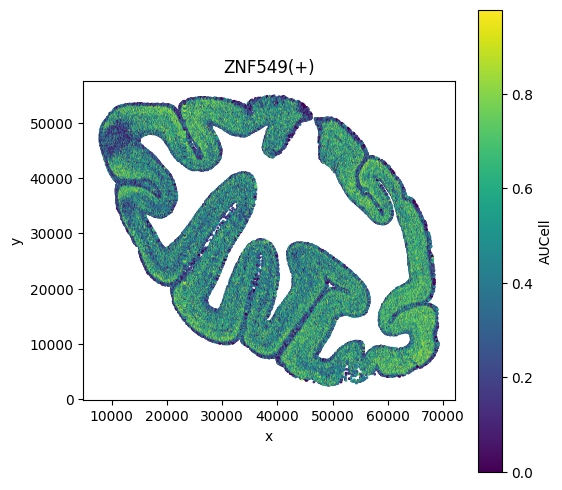

In [6]:
regulon = auc_mtx.var().idxmax()
xy = adata.obsm["spatial"]
fig, ax = plt.subplots(figsize=(6, 6))
points = ax.scatter(xy[:, 0], xy[:, 1], c=adata.obsm["auc_mtx"][regulon], s=1, cmap="viridis", rasterized=True)
ax.set(title=regulon, xlabel="x", ylabel="y", aspect="equal")
fig.colorbar(points, ax=ax, label="AUCell")
fig.savefig(out / "T577_SpaGRN_bin100_lowdown.regulon_activity.pdf", bbox_inches="tight")
plt.show()
